### pip install

In [1]:
!pip install torch matplotlib

### configuration.py

In [2]:
%%writefile configuration.py
# main.py
WIDTH = 1200
HEIGHT = 600
FPS = 5
RENDER = False

DATA_FONT = None
SCORE_FONT = None
EPISODE_LENGTH_MULTIPLIER = FPS / 2.5

MAX_DEVIATION = 10
DISTANCE_CHECKPOINTS = 3

# plane.py
THRUST_CHANGE_RATE = 2      # Rate of thrust adjustment
MAX_SPEED = 100             # Maximum velocity in m/s
FLIGHT_DRAG = 0.25          # DRAG_COEFFICIENT = 0.25  # Air drag proportional to v²
GROUND_DRAG = 0.05
MAX_ACCELERATION = 5        # Maximum acceleration in m/s²
BRAKE_MULTIPLIER = 0.98     # Speed reduction factor when braking
FRICTION = 10               # Ground friction proportional to velocity
PIXEL_TO_METRE = 2.5        # 1 pixel = 2.5 meters
TIME_STEP = 1 / FPS         # Frame time (30 FPS)
MAX_TURN_ANGLE = 1          # Maximum turn angle in degrees
TURN_SPEED_SCALING = 0.05   # Scaling factor for speed-dependent turning
SLOW_DISTANCE = 10          # Distance at which to slow down to stop
SLOW_SPEED = 15             # knots
TAXI_SPEED = 25             # knots


Overwriting configuration.py


### utils.py

In [3]:
%%writefile utils.py
import math


def to_knots(mps):
    return mps * 1.94384


def to_mps(knots):
    return knots / 1.94384


def distance_between(x1, y1, x2, y2):
    return math.sqrt((x1 - x2) ** 2 + (y1 - y2) ** 2)


def closest_point_on_line(x, y, a1, a2, b1, b2):
    # Vector AB
    ABx, ABy = b1 - a1, b2 - a2
    # Vector AP
    APx, APy = x - a1, y - a2
    # Length squared of AB
    AB_len_sq = ABx**2 + ABy**2

    if AB_len_sq == 0:  # A and B are the same point
        return (a1, a2, math.sqrt((x - a1) ** 2 + (y - a2) ** 2))

    # Projection factor t
    t = (APx * ABx + APy * ABy) / AB_len_sq
    # Clamp t to the range [0, 1]
    t = max(0, min(1, t))

    # Closest point on AB
    closest_x = a1 + t * ABx
    closest_y = a2 + t * ABy

    # Distance to closest point
    distance = math.sqrt((x - closest_x) ** 2 + (y - closest_y) ** 2)

    return (closest_x, closest_y, distance)


def get_angle_between_points(point1, point2):
    return math.degrees(math.atan2(point2.y - point1.y, point2.x - point1.x))


def get_distance_from_path(plane, point1, point2):
    _, _, distance = closest_point_on_line(
        plane.x, plane.y, point1.x, point1.y, point2.x, point2.y
    )
    return distance


import matplotlib.pyplot as plt
from IPython.display import clear_output

plt.ion()


def plot(scores, mean_scores):
    clear_output(wait=True)  # Clears the previous output
    plt.figure(figsize=(8, 5))  # Set figure size
    plt.clf()
    plt.title("Training Progress")
    plt.xlabel("Number of Games")
    plt.ylabel("Score")
    plt.plot(scores, label="Score", color="blue")
    plt.plot(mean_scores, label="Mean Score", color="red")
    plt.legend()

    if scores:
        plt.text(len(scores) - 1, scores[-1], f"{scores[-1]:.3f}", color="blue")
    if mean_scores:
        plt.text(
            len(mean_scores) - 1, mean_scores[-1], f"{mean_scores[-1]:.3f}", color="red"
        )

    plt.show()
    plt.pause(0.1)

Overwriting utils.py


### plane.py

In [4]:
%%writefile plane.py
import math
import configuration as config
from configuration import *
from utils import *

if config.RENDER:
    import pygame


class Plane:
    def __init__(self, x, y, heading):
        self.x = x
        self.y = y
        self.heading = heading
        self.thrust = 0
        self.speed = 0
        self.drag = config.GROUND_DRAG

        if config.RENDER:
            self.image = pygame.image.load("images/plane.png")

    def draw(self, window):
        if not config.RENDER:
            return  # Skip drawing if rendering is disabled

        rotated_image = pygame.transform.rotate(self.image, -self.heading)
        rotated_rect = rotated_image.get_rect(center=(self.x, self.y))
        window.blit(rotated_image, rotated_rect.topleft)

        data = config.DATA_FONT.render(
            f"{to_knots(self.speed):.0f} kts {self.thrust}%", True, (0, 0, 0)
        )
        window.blit(data, (self.x - 15, self.y - 20))

    def thrust_up(self):
        self.thrust += THRUST_CHANGE_RATE
        if self.thrust > 100:
            self.thrust = 100

    def thrust_down(self):
        self.thrust -= THRUST_CHANGE_RATE
        if self.thrust < 0:
            self.thrust = 0
            self.brake()

    def brake(self):
        self.speed *= BRAKE_MULTIPLIER
        if self.speed <= 0.1:
            self.speed = 0

    def update_speed(self):
        acceleration = (self.thrust / 100) * MAX_ACCELERATION

        self.speed += acceleration * TIME_STEP
        self.speed -= self.drag * self.speed * TIME_STEP

        if self.speed > MAX_SPEED:
            self.speed = MAX_SPEED
        elif self.speed < 0:
            self.speed = 0

    def move(self):
        self.update_speed()

        radian_heading = math.radians(self.heading)
        self.x += (self.speed / PIXEL_TO_METRE) * math.sin(radian_heading) * TIME_STEP
        self.y -= (self.speed / PIXEL_TO_METRE) * math.cos(radian_heading) * TIME_STEP

    def get_turn_angle(self):
        if self.speed == 0:
            return 0
        return MAX_TURN_ANGLE / (1 + TURN_SPEED_SCALING * self.speed)

    def turn_left(self):
        turn_angle = self.get_turn_angle()
        self.heading = (self.heading - turn_angle) % 360

    def turn_right(self):
        turn_angle = self.get_turn_angle()
        self.heading = (self.heading + turn_angle) % 360

Overwriting plane.py


### game.py

In [5]:
%%writefile game.py
import random
import math
import configuration as config
from plane import Plane
from utils import (
    distance_between,
    to_mps,
    to_knots,
    get_distance_from_path,
    closest_point_on_line,
)
import numpy as np

if config.RENDER:
    import pygame

    pygame.init()
    config.DATA_FONT = pygame.font.Font("arial.ttf", 12)
    config.SCORE_FONT = pygame.font.Font("arial.ttf", 23)


class Node:
    def __init__(self, x, y):
        self.x = x
        self.y = y


class IdealPosition:
    def __init__(self, x, y, path):
        self.x = x
        self.y = y
        self.heading = 0
        self.speed = 0
        self.path_index = 1
        self.path = path
        self.destination = path[self.path_index]

    def move(self):
        end_x, end_y = self.destination.x, self.destination.y
        distance_next = distance_between(self.x, self.y, end_x, end_y)

        prev_x, prev_y = (
            self.path[self.path_index - 1].x,
            self.path[self.path_index - 1].y,
        )
        distance_prev = distance_between(self.x, self.y, prev_x, prev_y)

        if distance_next < config.SLOW_DISTANCE or distance_prev < config.SLOW_DISTANCE:
            self.speed = to_mps(config.SLOW_SPEED)
        else:
            self.speed = to_mps(config.TAXI_SPEED)

        radian_heading = math.atan2(end_y - self.y, end_x - self.x)
        self.heading = (math.degrees(radian_heading) + 90) % 360

        self.x += (
            (self.speed / config.PIXEL_TO_METRE)
            * math.cos(radian_heading)
            * config.TIME_STEP
        )
        self.y += (
            (self.speed / config.PIXEL_TO_METRE)
            * math.sin(radian_heading)
            * config.TIME_STEP
        )

        if distance_next < self.speed * config.TIME_STEP:
            self.x = end_x
            self.y = end_y
            self.speed = 0

    def update_destination(self):
        self.path_index += 1
        if self.path_index >= len(self.path):
            self.path_index = len(self.path) - 1
        self.destination = self.path[self.path_index]

    def draw(self, window):
        if not config.RENDER:
            return

        pygame.draw.circle(
            window,
            (255, 255, 0),
            (int(self.x), int(self.y)),
            config.MAX_DEVIATION,
        )


class GroundTrainingAI:

    def __init__(self, w=config.WIDTH, h=config.HEIGHT):
        self.width = w
        self.height = h
        if config.RENDER:
            self.display = pygame.display.set_mode((self.width, self.height))
            pygame.display.set_caption("Training AI")
            self.clock = pygame.time.Clock()
        self.reset()

    def reset(self):
        self.score = 0
        self.frame_iteration = 0
        self.path, self.path_distance = self.generate_path()
        start_radian = math.atan2(
            self.path[1].y - self.path[0].y, self.path[1].x - self.path[0].x
        )
        start_heading = (
            (math.degrees(start_radian) + 90) + random.randint(-60, 60)
        ) % 360
        self.plane = Plane(self.path[0].x, self.path[0].y, start_heading)
        self.ideal_position = IdealPosition(self.path[0].x, self.path[0].y, self.path)

        self.previous_node = self.path[0]
        self.next_node = self.path[1]
        self.previous_distance = distance_between(
            self.previous_node.x,
            self.previous_node.y,
            self.next_node.x,
            self.next_node.y,
        )

    def generate_path(
        self, num_nodes=4, min_distance=50, max_distance=150, max_attempts=20
    ):
        current_path = []

        # Generate the first node randomly
        start_x = random.randint(50, self.width - 50)
        start_y = random.randint(50, self.height - 50)
        current_path.append(Node(start_x, start_y))

        # Set a random initial heading (0° = right, 90° = down, 180° = left, 270° = up)
        heading = random.uniform(0, 360)

        i = 1  # Start from second node
        while i < num_nodes:
            attempts = 0  # Reset attempt counter
            valid_node_found = False

            while attempts < max_attempts:
                attempts += 1

                # Choose a random angle within a forward-facing range (-90° to +90°)
                angle_offset = random.uniform(-90, 90)
                new_heading = (
                    heading + angle_offset
                ) % 360  # Keep heading within 0-360°

                # Convert heading to movement vector
                radian_angle = math.radians(new_heading)
                distance = random.randint(min_distance, max_distance)
                new_x = int(current_path[-1].x + distance * math.cos(radian_angle))
                new_y = int(current_path[-1].y + distance * math.sin(radian_angle))

                # Ensure the new point is within bounds
                if 50 <= new_x <= self.width - 50 and 50 <= new_y <= self.height - 50:
                    current_path.append(Node(new_x, new_y))
                    heading = new_heading  # Update heading to maintain smooth path
                    valid_node_found = True
                    break  # Exit loop once a valid node is found

            if not valid_node_found:
                while True:
                    x = random.randint(0 + 50, self.width - 50)
                    y = random.randint(0 + 50, self.height - 50)

                    if (
                        i == 0
                        or distance_between(
                            x, y, current_path[-1].x, current_path[-1].y
                        )
                        > min_distance
                        and distance_between(
                            x, y, current_path[-1].x, current_path[-1].y
                        )
                        < max_distance
                    ):
                        current_path.append(Node(x, y))
                        break

            i += 1

        # Compute total distance of the path
        total_distance = sum(
            distance_between(
                current_path[i].x,
                current_path[i].y,
                current_path[i + 1].x,
                current_path[i + 1].y,
            )
            for i in range(len(current_path) - 1)
        )

        return current_path, total_distance

    def play_step(self, action):
        self.frame_iteration += 1
        state = self.get_state()

        if config.RENDER:
            for event in pygame.event.get():
                if event.type == pygame.QUIT:
                    pygame.quit()
                    quit()
                elif event.type == pygame.KEYDOWN:
                    if event.key == pygame.K_UP:
                        action[0] = 1
                    elif event.key == pygame.K_DOWN:
                        action[1] = 1
                    elif event.key == pygame.K_LEFT:
                        action[2] = 1
                    elif event.key == pygame.K_RIGHT:
                        action[3] = 1

        self._move(action)

        if config.RENDER:
            self._update_display()

        reward = 0
        game_over = False

        if self._is_idle() or self._is_too_far():
            game_over = True
            reward = -5
            self.score += reward
            return reward, game_over, self.score

        if self._is_reached()[0]:
            reward += 5
            self.ideal_position.update_destination()
            if self._is_reached()[1]:
                game_over = True
                self.score += reward
                return reward, game_over, self.score

        self.plane.speed = to_mps(10)
        if state[-3] < -0.03:  # needs to turn left
            if action[1] == 1:
                reward += 0.5
            else:
                reward -= 1
        elif state[-3] > 0.03:  # needs to turn right
            if action[2] == 1:
                reward += 0.5
            else:
                reward -= 1
        else:
            reward += 0.1

        self.score += reward
        return reward, game_over, self.score

    def _update_display(self):
        if not config.RENDER:
            return

        self.display.fill((255, 255, 255))

        for i in range(len(self.path) - 1):
            pygame.draw.line(
                self.display,
                (0, 0, 255),
                (self.path[i].x, self.path[i].y),
                (self.path[i + 1].x, self.path[i + 1].y),
                1,
            )

        pygame.draw.circle(
            self.display,
            (0, 255, 0),
            (self.next_node.x, self.next_node.y),
            config.MAX_DEVIATION,
        )

        for node in self.path:
            pygame.draw.circle(self.display, (255, 0, 0), (node.x, node.y), 3)

        self.ideal_position.draw(self.display)

        self.plane.draw(self.display)

        score_text = config.SCORE_FONT.render(
            f"Score: {self.score:.2f}",
            True,
            (0, 0, 0),
        )
        frame_text = config.SCORE_FONT.render(
            f"Frame: {self.frame_iteration}/{config.EPISODE_LENGTH_MULTIPLIER * self.path_distance:.0f}",
            True,
            (0, 0, 0),
        )

        self.display.blit(score_text, (0, 0))
        self.display.blit(frame_text, (0, 30))

        pygame.display.update()
        self.clock.tick(config.FPS)

    def _is_ideal(self):
        distance_to_ideal = distance_between(
            self.plane.x, self.plane.y, self.ideal_position.x, self.ideal_position.y
        )

        return distance_to_ideal < config.MAX_DEVIATION

    def _update_close_distance(self):
        if self._is_closer():
            distance_to_next = distance_between(
                self.plane.x, self.plane.y, self.next_node.x, self.next_node.y
            )
            self.previous_distance = distance_to_next

    def _is_too_far(self):
        distance_from_path = get_distance_from_path(
            self.plane, self.previous_node, self.next_node
        )

        return distance_from_path > config.MAX_DEVIATION

    def _is_near_path(self):
        distance_from_path = get_distance_from_path(
            self.plane, self.previous_node, self.next_node
        )

        return distance_from_path < config.MAX_DEVIATION

    def _is_closer(self):
        distance_to_next = distance_between(
            self.plane.x, self.plane.y, self.next_node.x, self.next_node.y
        )

        if self.previous_distance - distance_to_next >= config.DISTANCE_CHECKPOINTS:
            return True
        else:
            return False

    def _is_reached(self):
        radius = config.MAX_DEVIATION

        is_reached = (
            distance_between(
                self.plane.x, self.plane.y, self.next_node.x, self.next_node.y
            )
            < radius
        )

        is_reached_end = False

        if is_reached:
            index = self.path.index(self.next_node)
            self.previous_node = self.path[index]

            if index + 1 < len(self.path):
                self.next_node = self.path[index + 1]
            else:
                is_reached_end = True

        return is_reached, is_reached_end

    def _is_out_of_bounds(self):
        return (
            self.plane.x > self.width
            or self.plane.x < 0
            or self.plane.y > self.height
            or self.plane.y < 0
        )

    def _is_idle(self):
        return (
            self.frame_iteration > config.EPISODE_LENGTH_MULTIPLIER * self.path_distance
        )

    def _move(self, action):
        if action[0] == 1:
            pass
        elif action[1] == 1:
            self.plane.turn_left()
        elif action[2] == 1:
            self.plane.turn_right()

        self.plane.move()
        self.ideal_position.move()

    def _get_side_of_path(self):
        """
        Determines if the plane is to the left or right of the ideal path.

        Returns:
            -1 if the plane is on the left,
            1 if the plane is on the right,
            0 if exactly on the path.
        """

        plane, previous_node, next_node = self.plane, self.previous_node, self.next_node

        # Path vector (P1 → P2)
        path_vector = np.array(
            [next_node.x - previous_node.x, next_node.y - previous_node.y]
        )

        # Plane vector (P1 → Plane Position)
        plane_vector = np.array([plane.x - previous_node.x, plane.y - previous_node.y])

        # Compute 2D cross product (determines left or right)
        cross_product = np.cross(path_vector, plane_vector)

        if cross_product > 5:
            return 1  # Plane is to the right of the path
        elif cross_product < 5:
            return -1  # Plane is to the left of the path
        else:
            return 0  # Plane is exactly on the path)

    def get_state(self):
        angles = [-90, -60, -30, 0, 30, 60, 90]
        distances = []

        plane_x, plane_y = self.plane.x, self.plane.y

        for angle in angles:
            # Compute absolute angle in world space
            absolute_angle = (self.plane.heading + angle - 90) % 360
            radian_angle = math.radians(absolute_angle)

            # Direction vector (unit length)
            dx, dy = math.cos(radian_angle), math.sin(radian_angle)

            # Start at the plane's position
            current_x, current_y = plane_x, plane_y
            step_size = 1  # Step 1 pixel at a time

            while True:
                # Move along the direction vector
                current_x += dx * step_size
                current_y += dy * step_size

                # Compute distance to closest point on the path
                closest_x, closest_y, distance_to_path = closest_point_on_line(
                    current_x,
                    current_y,
                    self.previous_node.x,
                    self.previous_node.y,
                    self.next_node.x,
                    self.next_node.y,
                )

                # Stop when we reach the max deviation boundary
                if distance_to_path >= config.MAX_DEVIATION:
                    break

            # Compute the final distance from the plane to this intersection
            distance_to_boundary = distance_between(
                plane_x, plane_y, current_x, current_y
            )
            distances.append(distance_to_boundary)

        if config.RENDER:
            pygame.draw.circle(
                self.display, (0, 0, 255), (int(current_x), int(current_y)), 3
            )
            pygame.display.update()

        # Calculate the angle to the next checkpoint
        delta_x = self.next_node.x - self.plane.x
        delta_y = self.next_node.y - self.plane.y
        angle_to_checkpoint = (math.degrees(math.atan2(delta_y, delta_x)) + 360) % 360

        # Get the difference in angles (relative to the plane’s heading)
        angle_diff = (angle_to_checkpoint - self.plane.heading + 90) % 360

        # Normalize the angle difference to the range [-180, 180]
        if angle_diff > 180:
            angle_diff -= 360

        # Scale the angle difference to the range [-1, 1]
        turn_direction = angle_diff / 180

        normalized_distances = np.array(distances) / 150.0
        normalized_speed = self.plane.speed / 100.0

        distance_to_checkpoint = distance_between(
            self.plane.x, self.plane.y, self.next_node.x, self.next_node.y
        )
        normalized_distance_to_checkpoint = distance_to_checkpoint / 150.0

        state = np.append(
            normalized_distances,
            [turn_direction, normalized_speed, normalized_distance_to_checkpoint],
        )
        state = np.append(
            normalized_distances,
            [
                turn_direction,
                normalized_speed,
                normalized_distance_to_checkpoint,
            ],
        )

        return state.astype(np.float32)


# if __name__ == "__main__":
#     env = GroundTrainingAI()
#     env.reset()

#     while True:
#         env.get_state()
#         reward, game_over, score = env.play_step([0, 0, 0, 0, 0])
#         if game_over:
#             env.reset()
#             break

Overwriting game.py


### model.py

In [6]:
%%writefile model.py
import torch
import torch.nn as nn
import torch.optim as optim
import os


class Linear_QNet(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super(Linear_QNet, self).__init__()
        self.linear1 = nn.Linear(input_size, hidden_size)
        self.output = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        x = torch.relu(self.linear1(x))
        x = self.output(x)
        return x

    def save(self, file_name="model.pth"):
        model_folder_path = "./model"
        if not os.path.exists(model_folder_path):
            os.makedirs(model_folder_path)
        file_path = os.path.join(model_folder_path, file_name)
        torch.save(self.state_dict(), file_path)

    def load(self, file_name="model.pth"):
        model_folder_path = "./model"
        file_path = os.path.join(model_folder_path, file_name)
        if os.path.exists(file_path):
            self.load_state_dict(torch.load(file_path))
        else:
            print(
                f"Model file '{file_path}' does not exist. Starting with a new model."
            )


class QTrainer:
    def __init__(self, model, lr, gamma):
        self.lr = lr
        self.gamma = gamma
        self.model = model
        self.optimiser = optim.Adam(self.model.parameters(), lr=self.lr)
        self.criterion = nn.MSELoss()

    def train_step(self, state, action, reward, next_state, done, target_model):
        device = next(self.model.parameters()).device

        state = torch.tensor(state, dtype=torch.float32, device=device)
        action = torch.tensor(action, dtype=torch.float32, device=device)
        reward = torch.tensor(reward, dtype=torch.float32, device=device)
        next_state = torch.tensor(next_state, dtype=torch.float32, device=device)

        # Predict Q values (current state)
        prediction = self.model(state)
        target = prediction.clone().detach()

        for idx in range(len(done)):
            Q_new = reward[idx]
            if not done[idx]:
                # Q_new = reward[idx] + self.gamma * torch.max(self.model(next_state[idx]))
                Q_new = reward[idx] + self.gamma * torch.max(target_model(next_state[idx]))
            action_index = torch.argmax(action[idx]).item()
            target[idx][action_index] = Q_new

        self.optimiser.zero_grad()
        loss = self.criterion(target, prediction)
        loss.backward()
        self.optimiser.step()

Overwriting model.py


### agent.py

In [7]:
%%writefile agent.py
import torch
import random
import time
import numpy as np
import configuration as config
from collections import deque
from game import GroundTrainingAI
from model import Linear_QNet, QTrainer
from utils import plot

# Constants
MAX_MEMORY = 500_000
BATCH_SIZE = 5_000
LR = 0.001


# Agent Class
class Agent:

    def __init__(self):
        self.n_games = 0
        self.epsilon = 0  # randomness (exploration rate)
        self.gamma = 0.99  # discount rate
        self.memory = deque(maxlen=MAX_MEMORY)  # Replay memory
        self.model = Linear_QNet(10, 16, 3).to(self.get_device())
        self.target_model = Linear_QNet(10, 16, 3).to(self.get_device())
        self.update_target_model()
        self.trainer = QTrainer(self.model, lr=LR, gamma=self.gamma)

    def get_device(self):
        # MPS -> CUDA -> CPU
        if torch.backends.mps.is_available() and torch.backends.mps.is_built():
            return torch.device("mps")
        elif torch.cuda.is_available():
            return torch.device("cuda")
        else:
            return torch.device("cpu")

    def remember(self, state, action, reward, next_state, done):
        self.memory.append((state, action, reward, next_state, done))

    def update_target_model(self):
        self.target_model.load_state_dict(self.model.state_dict())

    def train_long_memory(self):
        if len(self.memory) > BATCH_SIZE:
            mini_sample = random.sample(self.memory, BATCH_SIZE)
        else:
            mini_sample = self.memory

        states, actions, rewards, next_states, dones = zip(*mini_sample)
        states = np.array(states, dtype=np.float32)
        actions = np.array(actions, dtype=np.float32)
        rewards = np.array(rewards, dtype=np.float32)
        next_states = np.array(next_states, dtype=np.float32)
        dones = np.array(dones, dtype=np.float32)

        self.trainer.train_step(
            states, actions, rewards, next_states, dones, self.target_model
        )

    def train_short_memory(self, state, action, reward, next_state, done):
        state = np.array([state], dtype=np.float32)
        action = np.array([action], dtype=np.float32)
        reward = np.array([reward], dtype=np.float32)
        next_state = np.array([next_state], dtype=np.float32)
        done = np.array([done], dtype=np.float32)
        self.trainer.train_step(
            state, action, reward, next_state, done, self.target_model
        )

    def get_action(self, state):
        self.epsilon = max(0.05, 1.0 * (0.996**self.n_games))
        final_move = [0, 0, 0]

        # Exploration vs. exploitation
        if random.random() < self.epsilon:
            move = random.randint(0, len(final_move) - 1)
        else:
            state0 = torch.tensor(state, dtype=torch.float).to(self.get_device())
            prediction = self.model(state0)
            move = torch.argmax(prediction).item()

        final_move[move] = 1
        return final_move


def train():
    agent = Agent()
    game = GroundTrainingAI()

    record = float("-inf")
    total_score = 0
    plot_scores = []
    plot_mean_scores = []

    while True:
        start_time = time.time()

        state_old = game.get_state()
        final_move = agent.get_action(state_old)
        reward, done, score = game.play_step(final_move)
        state_new = game.get_state()

        agent.train_short_memory(state_old, final_move, reward, state_new, done)
        agent.remember(state_old, final_move, reward, state_new, done)

        if done:
            game.reset()
            agent.n_games += 1
            agent.train_long_memory()

            if score > record:
                record = score
                agent.model.save()
            elif agent.n_games % 250 == 0:
                agent.model.save()

            total_score += score
            mean_score = total_score / agent.n_games
            plot_scores.append(score)
            plot_mean_scores.append(mean_score)

            end_time = time.time()
            duration = end_time - start_time

            if agent.n_games % 5 == 0:
                if config.RENDER:
                    print(f"{agent.n_games}: \tScore: {score:.2f} \tAvg: {mean_score:.2f} \tMem: {len(agent.memory)} \tDuration: {duration:.2f}s")
                else:
                    agent.update_target_model()
                    plot(plot_scores, plot_mean_scores)


def test_model(model_file="testmodel.pth", num_test_games=10):
    game = GroundTrainingAI()

    input_size = 10
    hidden_size = 8
    output_size = 5

    model = Linear_QNet(input_size, hidden_size, output_size)
    model.load(model_file)
    model.eval()

    for game_idx in range(1, num_test_games + 1):
        game.reset()
        total_score = 0
        done = False

        while not done:
            state = np.array(game.get_state()).astype(np.float32)
            state_tensor = torch.tensor(state, dtype=torch.float).unsqueeze(0)

            with torch.no_grad():
                prediction = model(state_tensor)

            action = torch.argmax(prediction).item()
            action_vector = [0] * output_size
            action_vector[action] = 1

            reward, done, score = game.play_step(action_vector)

            total_score += reward

        print(f"Test Game {game_idx}: Score = {total_score}")


# if __name__ == "__main__":
    # train()
    # test_model()

Overwriting agent.py


### Training

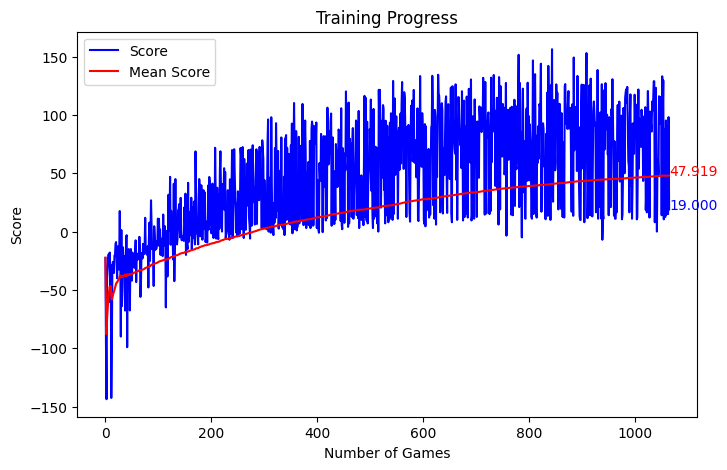

KeyboardInterrupt: 

In [8]:
from agent import train
train()